# ESCM 2.0 — Independent microcircuit audit

**Question.** Why did the scheduler-free Brian2 model and the independent NumPy model in notebook 11 produce different spikes? Before studying persistence or spatial representation, verify that both implementations execute the **same mathematical model and the same defined discrete-time event convention**.

This notebook deliberately uses conventional Brian2 `NeuronGroup`, `SpikeGeneratorGroup` and `Synapses` only. **No `P` gate, custom event, modified Brian2 backend, custom scheduling order, or fitted parameters.** `StateMonitor(..., when="end")` is used only for observation; it does not change dynamics.

We proceed from isolated integration to a recurrent microcircuit and identify the **first mismatching timestep**. Once these agree, we check small timestep changes. A match verifies a *finite set of clocked computations*, not equivalence to an ideal continuous-time spiking network.

The setup reproduces notebook 11's scheduler-free parameters: $\tau_m=10$ ms, $\tau_X=\tau_E=5$ ms, $\tau_I=12$ ms, $v_{\rm th}=1$, external increment 6, self-excitatory increment 6. The NumPy reference uses no Brian2 code, units or solver.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import brian2 as b2
from scipy.linalg import expm

b2.prefs.codegen.target = "numpy"

tau_m, tau_x, tau_e, tau_i = 10.0, 5.0, 5.0, 12.0  # ms
threshold = 1.0
input_weight, self_weight = 6.0, 6.0
dt_ms, duration_ms = 0.1, 40.0

print(f"Brian2 {b2.__version__}, NumPy {np.__version__}")
print("Time constants (ms):", tau_m, tau_x, tau_e, tau_i)

Brian2 2.10.1, NumPy 2.5.4
Time constants (ms): 10.0 5.0 5.0 12.0


## 1. Independently check the exact subthreshold update

For the state $z=(v,X,E,I)^T$ and no spikes,

$$
\dot z = A z, \qquad
A=\begin{pmatrix}
-1/\tau_m & 1/\tau_m & 1/\tau_m & -1/\tau_m\\
0 & -1/\tau_X & 0 & 0\\
0 & 0 & -1/\tau_E & 0\\
0 & 0 & 0 & -1/\tau_I
\end{pmatrix}.
$$

The exact state transition is $z(t+\Delta t)=e^{A\Delta t}z(t)$. This is independently available from `scipy.linalg.expm`. The corresponding closed-form membrane contributions are

$$
 b_Z = \begin{cases}
 \frac{\tau_Z}{\tau_Z-\tau_m}(e^{-\Delta t/\tau_Z}-e^{-\Delta t/\tau_m}), &\tau_Z\neq\tau_m,\\
 \frac{\Delta t}{\tau_m}e^{-\Delta t/\tau_m}, &\tau_Z=\tau_m.
 \end{cases}
$$

This checks the **equations themselves** before introducing threshold/reset or synaptic event timing. We also explicitly test the equal-time-constant limit, which caused difficulties with notebook 11's earlier Brian2 symbolic update.

In [2]:
def transition(dt, taus):
    tm, tx, te, ti = taus
    am = np.exp(-dt / tm)
    def b(t):
        if np.isclose(t, tm):
            return (dt / tm) * am
        return (t / (t - tm)) * (np.exp(-dt / t) - am)
    M = np.zeros((4, 4))
    M[0] = [am, b(tx), b(te), -b(ti)]
    M[1, 1] = np.exp(-dt / tx)
    M[2, 2] = np.exp(-dt / te)
    M[3, 3] = np.exp(-dt / ti)
    return M

for taus in ((tau_m, tau_x, tau_e, tau_i), (10.0, 10.0, 10.0, 10.0)):
    A = np.diag(-1 / np.asarray(taus, dtype=float))
    A[0, 1:] = [1 / taus[0], 1 / taus[0], -1 / taus[0]]
    expected = expm(A * dt_ms)
    measured = transition(dt_ms, taus)
    error = np.max(np.abs(expected - measured))
    print(f"Time constants {taus}: max transition-matrix error = {error:.2e}")
    assert error < 1e-12

Time constants (10.0, 5.0, 5.0, 12.0): max transition-matrix error = 2.79e-16
Time constants (10.0, 10.0, 10.0, 10.0): max transition-matrix error = 1.73e-18


### Critical audit correction: avoid reserved symbolic constants

The uploaded execution reveals that Brian2’s excitatory variable named `E` was **not behaving as a decaying state**. The first recorded value was approximately 2.664456, which equals $e\exp(-0.1/5)$, and it remained near that value instead of decaying. The identifiers `E` and `I` are also special constants in SymPy (Euler’s number and the imaginary unit). This strongly indicates a symbol-name collision in symbolic equation processing, rather than a genuine recurrent firing mechanism. To remove the ambiguity, the Brian2 model now uses `I_exc` and `I_inh` instead and explicitly initializes every state to zero. The NumPy reference retains its column-based arrays.

**Verification criterion:** the subthreshold test must have zero spikes and reproduce the NumPy state trajectory; all six microcircuits must then agree before any timestep conclusions are accepted.

## 2. Implement the same clocked network in Brian2 and plain NumPy

The common discrete-time contract is:

1. At clock timestamp $t_n$, integrate the four continuous states one step using their **pre-event** values.
2. Test the resulting voltage against the strict threshold $v>1$.
3. Apply incoming camera and recurrent synaptic increments for spikes whose timestamp is $t_n$.
4. Reset the voltage of neurons that spiked to zero.
5. Observe the resulting state at the **end** of that timestep.

This describes the normal Brian2 schedule for the network used here (without delays, refractory conditions, or custom scheduling). Events in `SpikeGeneratorGroup` with timestamp $t_n$ are delivered at the clock tick $n$; the neuron's integration over that tick has already taken place. **Do not pre-apply camera events at $t=0$ in the NumPy reference**—that was one possible discrepancy in notebook 11.

The independent reference directly executes this contract with NumPy arrays. Its state variables are dimensionless and time is measured in milliseconds; Brian2 uses explicit physical units. Each excitatory/inhibitory connection is a tuple `(source, target, weight)`. A self-connection is an ordinary excitatory autapse.

In [3]:
def run_brian(n, stimulus, excitation=(), inhibition=(), dt=dt_ms):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms
    ids, times = stimulus
    params = dict(
        tau_m_b=tau_m * b2.ms, tau_x_b=tau_x * b2.ms,
        tau_e_b=tau_e * b2.ms, tau_i_b=tau_i * b2.ms,
        threshold_b=threshold, input_weight_b=input_weight,
    )
    camera = b2.SpikeGeneratorGroup(n, np.asarray(ids, dtype=int), np.asarray(times) * b2.ms)
    neurons = b2.NeuronGroup(
        n,
        """dv/dt = (-v + X + I_exc - I_inh)/tau_m_b : 1
        dX/dt = -X/tau_x_b : 1
        dI_exc/dt = -I_exc/tau_e_b : 1
        dI_inh/dt = -I_inh/tau_i_b : 1""",
        threshold="v > threshold_b", reset="v = 0",
        method="exact", namespace=params,
    )
    feed = b2.Synapses(camera, neurons, on_pre="X_post += input_weight_b", namespace=params)
    feed.connect(j="i")
    synapses = []
    if excitation:
        exc = b2.Synapses(neurons, neurons, model="w : 1", on_pre="I_exc_post += w")
        exc.connect(i=[e[0] for e in excitation], j=[e[1] for e in excitation])
        exc.w = [e[2] for e in excitation]
        synapses.append(exc)
    if inhibition:
        inh = b2.Synapses(neurons, neurons, model="w : 1", on_pre="I_inh_post += w")
        inh.connect(i=[e[0] for e in inhibition], j=[e[1] for e in inhibition])
        inh.w = [e[2] for e in inhibition]
        synapses.append(inh)
    # Explicitly initialize all states; never rely on implicit defaults.
    neurons.v = 0
    neurons.X = 0
    neurons.I_exc = 0
    neurons.I_inh = 0
    assert np.allclose(neurons.v[:], 0)
    assert np.allclose(neurons.I_exc[:], 0)
    assert np.allclose(neurons.I_inh[:], 0)
    spikes = b2.SpikeMonitor(neurons)
    states = b2.StateMonitor(neurons, ("v", "X", "I_exc", "I_inh"), record=True, when="end")
    b2.Network(camera, neurons, feed, *synapses, spikes, states).run(duration_ms * b2.ms)
    return dict(
        spike_ticks=np.rint(np.asarray(spikes.t / b2.ms) / dt).astype(int),
        spike_ids=np.asarray(spikes.i, dtype=int),
        states=np.stack([np.asarray(getattr(states, key)) for key in ("v", "X", "I_exc", "I_inh")], axis=-1).transpose(1, 0, 2),
        # [time, neuron, state]
    )


def run_numpy(n, stimulus, excitation=(), inhibition=(), dt=dt_ms):
    steps = int(round(duration_ms / dt))
    ids, times = stimulus
    events = [[] for _ in range(steps)]
    for neuron, t in zip(ids, times):
        tick = int(round(t / dt))
        assert np.isclose(tick * dt, t) and tick < steps
        events[tick].append(int(neuron))

    M = transition(dt, (tau_m, tau_x, tau_e, tau_i))
    z = np.zeros((n, 4))  # [neuron, (v, X, I_exc, I_inh)]
    record = np.empty((steps, n, 4))
    spike_ticks, spike_ids = [], []
    for tick in range(steps):
        z = z @ M.T
        fired = np.flatnonzero(z[:, 0] > threshold)
        spike_ticks.extend([tick] * len(fired))
        spike_ids.extend(fired.tolist())
        for pre, post, weight in excitation:
            if pre in fired:
                z[post, 2] += weight
        for pre, post, weight in inhibition:
            if pre in fired:
                z[post, 3] += weight
        for neuron in events[tick]:
            z[neuron, 1] += input_weight
        z[fired, 0] = 0
        record[tick] = z

    return dict(spike_ticks=np.asarray(spike_ticks, dtype=int),
                spike_ids=np.asarray(spike_ids, dtype=int), states=record)

## 3. Verify each operation, from single-neuron response to recurrent competition

Six experiments separate possible sources of disagreement:

| Case | Connection pattern | What a discrepancy implicates |
|---|---|---|
| Subthreshold impulse | None | Input timing, integration, state recording |
| Suprathreshold impulse | None | Threshold and reset |
| One-neuron autapse | Self-excitation only | Recurrent spike delivery |
| Two-neuron excitation | Self-excitation plus lateral E | Excitatory propagation |
| Two-neuron inhibition | Self-excitation and cross-inhibition | Inhibitory updates |
| Three-neuron E–I | Combined recurrent interaction | Multiple concurrent pathways |

Compare **all four states at every tick** and every `(tick, neuron)` output-spike pair. Print the first state or spike mismatch. A state mismatch can precede a spike mismatch; it is the more useful diagnostic. There is deliberately **no tuning** to make the results match.

In [4]:
cases = {
    "subthreshold": (1, ([0], [1.0]), (), ()),
    "input_and_reset": (1, ([0], [1.0]), (), ()),
    "autapse": (1, ([0], [1.0]), ((0, 0, self_weight),), ()),
    "two_exc": (2, ([0], [1.0]), ((0, 0, self_weight), (0, 1, 2.0)), ()),
    "two_inh": (2, ([0, 1], [1.0, 8.0]),
                ((0, 0, self_weight), (1, 1, self_weight)),
                ((0, 1, 1.5), (1, 0, 1.5))),
    "three_EI": (3, ([0, 1], [1.0, 8.0]),
                 ((0, 0, self_weight), (1, 1, self_weight), (2, 2, self_weight),
                  (0, 1, 2.0), (1, 2, 2.0)),
                 ((0, 1, 1.5), (1, 0, 1.5))),
}

comparison = []
traces = {}
for name, (n, stimulus, exc, inh) in cases.items():
    # A subthreshold control requires a low-amplitude event in both models.
    original_input_weight = input_weight
    if name == "subthreshold":
        input_weight = 0.2
    try:
        brian = run_brian(n, stimulus, exc, inh)
        numpy_ref = run_numpy(n, stimulus, exc, inh)
    finally:
        input_weight = original_input_weight
    traces[name] = (brian, numpy_ref)
    identical_spikes = (np.array_equal(brian["spike_ticks"], numpy_ref["spike_ticks"])
                        and np.array_equal(brian["spike_ids"], numpy_ref["spike_ids"]))
    state_error = np.max(np.abs(brian["states"] - numpy_ref["states"]))
    first_bad_tick = np.flatnonzero(
        np.max(np.abs(brian["states"] - numpy_ref["states"]), axis=(1, 2)) > 1e-8
    )
    comparison.append(dict(case=name, brian_spikes=len(brian["spike_ticks"]),
                           numpy_spikes=len(numpy_ref["spike_ticks"]),
                           exact_spikes=identical_spikes, max_state_error=state_error,
                           first_state_mismatch=int(first_bad_tick[0]) if len(first_bad_tick) else None))

results = pd.DataFrame(comparison)
display(results)

,case,brian_spikes,numpy_spikes,exact_spikes,max_state_error,first_state_mismatch
0,subthreshold,0,0,True,1.387779e-16,None
1,input_and_reset,1,1,True,3.774758e-15,None
2,autapse,298,298,True,3.219647e-15,None
3,two_exc,440,440,True,3.441691e-15,None
4,two_inh,298,298,True,7.446488e-12,None
5,three_EI,764,764,True,1.484368e-13,None


## 4. Inspect the first mismatch rather than interpreting aggregate spikes

The following figure selects the **first case** for which either the state error exceeds $10^{-8}$ or the output spike trains differ. It plots all four states for the first neuron and reports the earliest divergent time. If every case passes, it displays the autapse experiment instead.

The error tolerance applies to floating-point **states**, not spikes. Spike indices and tick timestamps are compared exactly. A tiny state difference that does not alter firing should not be interpreted as a biological difference.

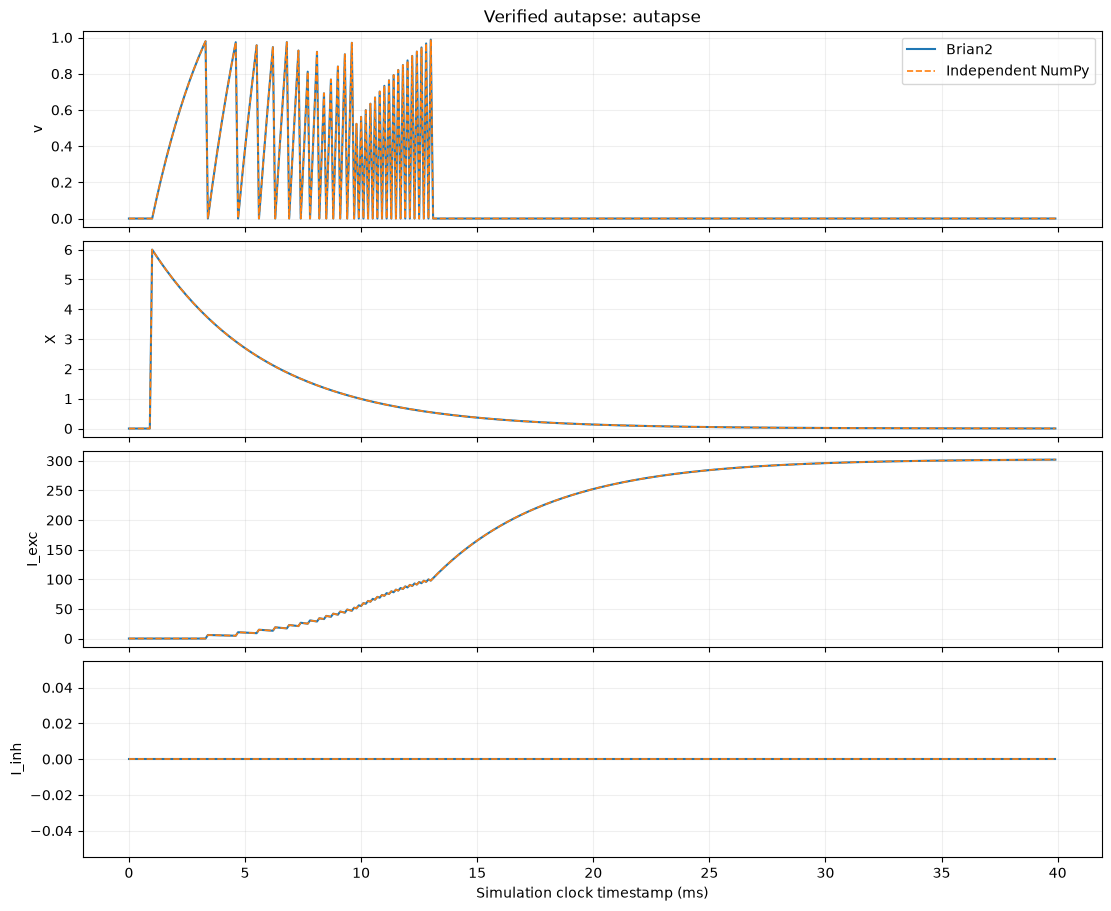

All six microcircuits match: exact output ticks and states within 1e-8.


In [5]:
failed = results[(~results.exact_spikes) | (results.max_state_error > 1e-8)]
case_name = failed.iloc[0]["case"] if len(failed) else "autapse"
a, b = traces[case_name]
times = np.arange(len(a["states"])) * dt_ms

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
for j, label in enumerate(("v", "X", "I_exc", "I_inh")):
    axes[j].plot(times, a["states"][:, 0, j], label="Brian2", linewidth=1.5)
    axes[j].plot(times, b["states"][:, 0, j], "--", label="Independent NumPy", linewidth=1.2)
    axes[j].set_ylabel(label)
    axes[j].grid(alpha=0.2)
axes[0].legend()
axes[0].set_title(f"{'First discrepancy' if len(failed) else 'Verified autapse'}: {case_name}")
axes[-1].set_xlabel("Simulation clock timestamp (ms)")
plt.show()

if len(failed):
    row = failed.iloc[0]
    print("First failing case:", row["case"], "first state mismatch tick:", row["first_state_mismatch"])
    print("Do not proceed to large-network stability claims before resolving this mismatch.")
else:
    print("All six microcircuits match: exact output ticks and states within 1e-8.")

## 5. Conditional timestep check for the independently verified microcircuit

If all microcircuit cases pass, repeat the autapse at timesteps $\{0.5,0.25,0.1,0.05,0.025\}$ ms. Physical input time and neuronal parameters remain fixed. Both simulators must agree at **each** timestep before interpreting a convergence trend.

If the comparison fails, we stop instead of presenting misleading convergence plots. Even when implementations agree, stable spike counts alone are insufficient to establish convergence of event timing or spatial representations.

,dt_ms,spikes,firing_rate_hz,first_spike_ms,exact_match,max_state_error
0,0.500,68,1700.0,3.500,True,1.221245e-15
1,0.250,127,3175.0,3.500,True,4.773959e-15
2,0.100,298,7450.0,3.400,True,3.219647e-15
3,0.050,562,14050.0,3.400,True,8.659740e-15
4,0.025,1054,26350.0,3.375,True,6.328271e-14


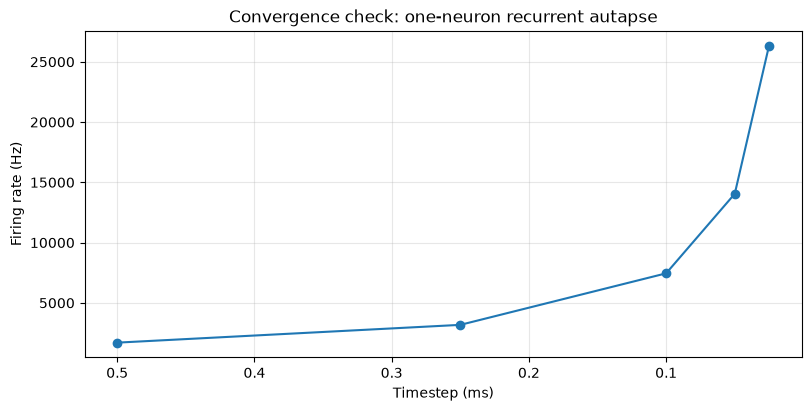

In [6]:
if len(failed):
    print("Timestep study skipped: independent reference is not yet verified.")
else:
    rows = []
    n, stimulus, exc, inh = cases["autapse"]
    for step in (0.5, 0.25, 0.1, 0.05, 0.025):
        a = run_brian(n, stimulus, exc, inh, dt=step)
        b = run_numpy(n, stimulus, exc, inh, dt=step)
        exact = (np.array_equal(a["spike_ticks"], b["spike_ticks"])
                 and np.array_equal(a["spike_ids"], b["spike_ids"]))
        error = np.max(np.abs(a["states"] - b["states"]))
        spike_times = a["spike_ticks"] * step
        rows.append(dict(dt_ms=step, spikes=len(spike_times),
                         firing_rate_hz=len(spike_times)/(duration_ms*0.001),
                         first_spike_ms=float(spike_times[0]) if len(spike_times) else np.nan,
                         exact_match=exact, max_state_error=error))
    convergence = pd.DataFrame(rows)
    display(convergence)
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.plot(convergence.dt_ms, convergence.firing_rate_hz, "o-")
    ax.invert_xaxis()
    ax.set(xlabel="Timestep (ms)", ylabel="Firing rate (Hz)",
           title="Convergence check: one-neuron recurrent autapse")
    ax.grid(alpha=0.3)
    plt.show()

## Interpretation and stopping rule

**Possible outcomes:**

- **Agreement in all cases:** the basic clocked LIF model, spike delivery, autapse, and E–I interactions are independently verified *for these six small examples*. We can then audit the full network and timestep convergence.
- **Disagreement without recurrence:** event delivery, threshold timing, or state recording requires correction.
- **Disagreement first appearing with recurrence:** inspect presynaptic event timing, reset semantics and current accumulation; do not attribute it to an emergent neuronal property.

**What this does not test:** the original ESCM's `P_ON`/`P_OFF` gate or its custom scheduling. That model is a distinct mathematical implementation and requires a separate, explicitly documented scheduler audit.

After this numerical contract passes, we can return to the biologically grounded architecture, without tuning the model to compensate for simulator-specific behavior.